In [1]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    roc_auc_score,
)
from sklearn.impute import SimpleImputer


Import embeddings and metadata

In [21]:
embfile = '../Results/sample_embeddings.csv'
metafile = '../data/2022-06_1_meta.csv'
meta_id_col = 'id'

In [22]:
embs = pd.read_csv(embfile,index_col=0)
embs.shape

(9992, 128)

In [23]:
metafile = pd.read_csv(metafile)
metafile.index = metafile[meta_id_col]
metafile = metafile.loc[embs.index]
metafile.shape

(9992, 10)

Necessary function

In [13]:
from typing import Tuple, Optional, Dict, Any

def split_train_val_test(
    X: np.ndarray,
    y: np.ndarray,
    seed: int,
    test_size: float,
    val_size: float,
    stratify: Optional[np.ndarray] = None,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    val_size is a fraction of the total dataset (not of train+val).
    """
    if not (0.0 < test_size < 1.0) or not (0.0 < val_size < 1.0) or (test_size + val_size >= 1.0):
        raise ValueError("Require 0<test_size<1, 0<val_size<1, and test_size+val_size<1")

    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=seed,
        stratify=stratify if stratify is not None else None
    )

    # val as fraction of total => within trainval, val_frac = val_size / (1 - test_size)
    val_frac = val_size / (1.0 - test_size)
    stratify_tv = None
    if stratify is not None:
        # need stratify for trainval subset
        # rebuild corresponding labels for trainval
        # easiest: compute using y_trainval if stratify==y
        stratify_tv = y_trainval

    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval,
        test_size=val_frac,
        random_state=seed,
        stratify=stratify_tv
    )
    return X_train, y_train, X_val, y_val, X_test, y_test

Regression model from embeddings

In [24]:
goal = 'Age'
metafileReg = metafile[metafile[goal].notna()]
metafileReg.shape

(9684, 10)

In [25]:
embsReg = embs.loc[metafileReg.index]
embsReg.shape

(9684, 128)

In [26]:
X = embsReg.to_numpy(dtype=float)
y = pd.to_numeric(metafileReg[goal], errors="coerce").to_numpy(dtype=float)
X_tr, y_tr, X_va, y_va, X_te, y_te = split_train_val_test(
            X, y,
            seed=123,
            test_size=0.2,
            val_size=0.1,
            stratify=None,
        )

In [27]:
def build_reg_model(alpha: float = 1.0) -> Pipeline:
    # Simple + strong baseline: impute -> standardize -> ridge regression
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler(with_mean=True, with_std=True)),
        ("model", Ridge(alpha=alpha, random_state=0)),
    ])

In [28]:
model = build_reg_model(alpha=1.0)
model.fit(X_tr, y_tr)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. I

In [29]:
def pcc(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    if y_true.size < 2:
        return float("nan")
    # if constant, corr undefined
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return float("nan")
    return float(np.corrcoef(y_true, y_pred)[0, 1])
def evaluate_reg(model: Pipeline, X: np.ndarray, y: np.ndarray) -> Dict[str, float]:
    pred = model.predict(X)
    return {
        "PCC": pcc(y, pred),
        "MSE": float(mean_squared_error(y, pred)),
        "MAE": float(mean_absolute_error(y, pred)),
    }

In [30]:
tr_m = evaluate_reg(model, X_tr, y_tr)
va_m = evaluate_reg(model, X_va, y_va)
te_m = evaluate_reg(model, X_te, y_te)

print("\n=== Regression ===")
print(f"Samples: total={len(y)} | train={len(y_tr)} | val={len(y_va)} | test={len(y_te)}")
print(f"Embedding dim: {X.shape[1]}")

def _fmt(m: Dict[str, float]) -> str:
    return f"PCC={m['PCC']:.4f}  MSE={m['MSE']:.4f}  MAE={m['MAE']:.4f}"

print("[Train] " + _fmt(tr_m))
print("[Val]   " + _fmt(va_m))
print("[Test]  " + _fmt(te_m))


=== Regression ===
Samples: total=9684 | train=6778 | val=969 | test=1937
Embedding dim: 128
[Train] PCC=0.5305  MSE=195.1410  MAE=11.1481
[Val]   PCC=0.5125  MSE=199.3321  MAE=11.4587
[Test]  PCC=0.4490  MSE=224.1285  MAE=11.3232


Classification model from embeddings

In [42]:
goal = 'Type'
ExceptSet = ['Other','Special','GD']
metafileCls = metafile[(metafile[goal].notna())&(~metafile[goal].isin(ExceptSet))]
metafileCls.shape

(9319, 10)

In [43]:
embsCls = embs.loc[metafileCls.index]
embsCls.shape

(9319, 128)

In [44]:
y = metafileCls[goal].astype(str).to_numpy()
le = LabelEncoder()
y = le.fit_transform(y)
n_classes = len(le.classes_)
print(n_classes)

5


In [45]:
X = embsCls.to_numpy(dtype=float)
X_tr, y_tr, X_va, y_va, X_te, y_te = split_train_val_test(
            X, y,
            seed=123,
            test_size=0.2,
            val_size=0.1,
            stratify=y,
        )

In [48]:
from collections import Counter
def build_clf_model(C: float = 1.0, max_iter: int = 5000) -> Pipeline:
    # Baseline classifier: impute → standardize → logistic regression
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler(with_mean=True, with_std=True)),
        ("model", LogisticRegression(
            C=C,
            max_iter=max_iter,
            solver="lbfgs",
            class_weight="balanced",
        )),
    ])
def evaluate_clf(model: Pipeline, X: np.ndarray, y: np.ndarray, n_classes: int) -> Dict[str, float]:
    pred = model.predict(X)
    acc = float(accuracy_score(y, pred))

    # AUC: requires probabilities
    auc = float("nan")
    try:
        if hasattr(model, "predict_proba"):
            proba = model.predict_proba(X)
            if n_classes == 2:
                # use positive class probability
                auc = float(roc_auc_score(y, proba[:, 1]))
            else:
                # multiclass macro OVR
                auc = float(roc_auc_score(y, proba, multi_class="ovr", average="macro"))
    except Exception:
        auc = float("nan")

    return {"AUC": auc, "ACC": acc}
def random_predict_with_prior(
    y_ref: np.ndarray,
    y_eval: np.ndarray,
    n_classes: int,
    seed: int = 0,
):
    """
    Random baseline that samples labels according to empirical class prior.

    y_ref  : labels used to estimate class prior (usually y_tr)
    y_eval : labels to evaluate against (y_tr / y_va / y_te)
    """
    rng = np.random.default_rng(seed)

    # empirical class distribution
    counts = Counter(y_ref)
    priors = np.array([counts.get(i, 0) for i in range(n_classes)], dtype=float)
    priors = priors / priors.sum()

    # random predictions
    y_rand = rng.choice(
        np.arange(n_classes),
        size=len(y_eval),
        p=priors
    )

    acc = accuracy_score(y_eval, y_rand)

    # random probabilities consistent with prior
    proba = np.tile(priors, (len(y_eval), 1))

    try:
        if n_classes == 2:
            auc = roc_auc_score(y_eval, proba[:, 1])
        else:
            auc = roc_auc_score(
                y_eval,
                proba,
                multi_class="ovr",
                average="macro"
            )
    except Exception:
        auc = float("nan")

    return {
        "ACC": acc,
        "AUC": auc,
        "priors": priors
    }
def fmt(m):
    auc = "nan" if np.isnan(m["AUC"]) else f"{m['AUC']:.4f}"
    return f"AUC={auc}  ACC={m['ACC']:.4f}"

In [49]:
model = build_clf_model()
model.fit(X_tr, y_tr)

tr_m = evaluate_clf(model, X_tr, y_tr, n_classes=n_classes)
va_m = evaluate_clf(model, X_va, y_va, n_classes=n_classes)
te_m = evaluate_clf(model, X_te, y_te, n_classes=n_classes)
rand_tr = random_predict_with_prior(y_tr, y_tr, n_classes, seed=0)
rand_va = random_predict_with_prior(y_tr, y_va, n_classes, seed=1)
rand_te = random_predict_with_prior(y_tr, y_te, n_classes, seed=2)

print("\n=== Classification (Model vs Random Prior Baseline) ===")
print(f"Classes ({n_classes}): {list(le.classes_)}")
print(f"Embedding dim: {X.shape[1]}\n")

print("[Train] Model :", fmt(tr_m))
print("        Random:", fmt(rand_tr), "\n")

print("[Val]   Model :", fmt(va_m))
print("        Random:", fmt(rand_va), "\n")

print("[Test]  Model :", fmt(te_m))
print("        Random:", fmt(rand_te))



=== Classification (Model vs Random Prior Baseline) ===
Classes (5): ['HRT1D', 'HRT2D', 'ND', 'T1D', 'T2D']
Embedding dim: 128

[Train] Model : AUC=0.8081  ACC=0.4809
        Random: AUC=0.5000  ACC=0.2641 

[Val]   Model : AUC=0.7768  ACC=0.4410
        Random: AUC=0.5000  ACC=0.2629 

[Test]  Model : AUC=0.7569  ACC=0.4362
        Random: AUC=0.5000  ACC=0.2586


Analysis For the DNB calculation

In [53]:
metricspth = '../Results/dnb_metrics.csv'
datapth = '../data/2022-06_1.csv'
metafile = '../data/2022-06_1_meta.csv'
meta_id_col = 'id'

In [52]:
metrics = pd.read_csv(metricspth,index_col=0)
metrics = metrics[metrics['num_patches']>200]
metrics.shape

(9752, 4)

In [55]:
data = pd.read_csv(datapth,index_col=0)
data = data.loc[metrics.index]
data.shape

(9752, 3458)

In [57]:
metainfo = pd.read_csv(metafile,index_col=0)
metainfo.index = metainfo[meta_id_col]
metainfo = metainfo.loc[metrics.index]
metainfo.shape

(9752, 9)

In [61]:
data = data[[str(x) for x in range(3456)]]
metrics['Mean']=data.mean(axis=1)

In [65]:
metrics['TIR']=(((data<=10)&(data>=3.9)).sum(axis=1))/((data.notna()).sum(axis=1))

In [69]:
metrics['SD']=data.std(axis=1)

In [70]:
metrics['Age'] = metainfo['Age']

In [71]:
import seaborn as sns

In [72]:
metrics = metrics[metrics['Age'].notna()]
metrics.shape

(9451, 8)

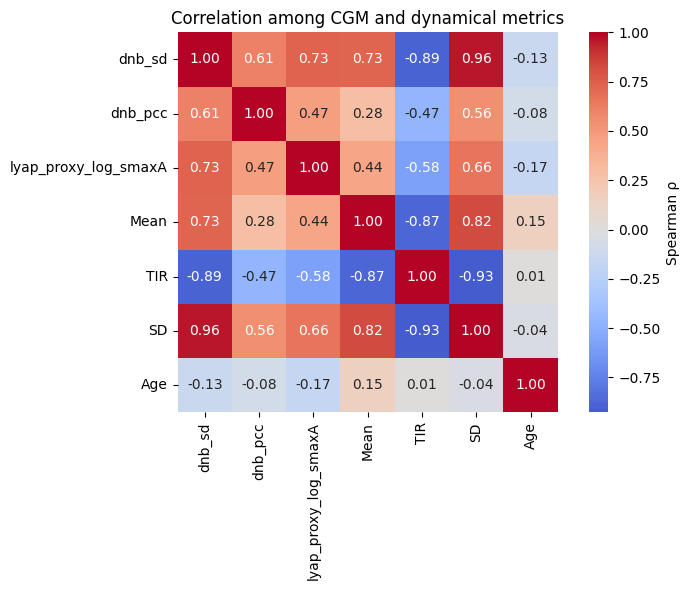

In [77]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns only
corr_cols = [
    'dnb_sd', 'dnb_pcc', 'lyap_proxy_log_smaxA',
    'Mean', 'TIR', 'SD', 'Age'
]

corr = metrics[corr_cols].corr(method='spearman')  # Spearman is safer

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={'label': 'Spearman ρ'}
)
plt.title("Correlation among CGM and dynamical metrics")
plt.tight_layout()
plt.savefig('../Results/Correlation.png')
plt.show()


In [85]:
metrics['Label'] = metainfo.loc[metainfo.index, 'Type']
df_bin = metrics[metrics['Label'].isin(['ND', 'T2D', 'HRT2D'])].copy()

label_map = {
    'ND': 0,
    'T2D': 1,
    'HRT2D': 2
}
df_bin['y'] = df_bin['Label'].map(label_map)

print(df_bin['Label'].value_counts())

Label
T2D      3090
ND       1559
HRT2D    1334
Name: count, dtype: int64


In [80]:
feature_groups = {
    "CGM_only": ['Mean', 'TIR', 'SD'],
    "Dynamical_only": ['dnb_sd', 'dnb_pcc', 'lyap_proxy_log_smaxA'],
    "CGM_plus_Dynamical": [
        'Mean', 'TIR', 'SD',
        'dnb_sd', 'dnb_pcc', 'lyap_proxy_log_smaxA'
    ],
}


In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, make_scorer
import numpy as np


In [101]:
def eval_multiclass_auc(df, features, y_col='y', n_splits=5):
    X = df[features + ['Age']].values
    y = df[y_col].values

    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(
                solver='lbfgs',
                max_iter=3000,
                class_weight='balanced'
            )
        )
    ])

    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    aucs = []

    for train_idx, test_idx in cv.split(X, y):
        pipe.fit(X[train_idx], y[train_idx])
        prob = pipe.predict_proba(X[test_idx])

        auc = roc_auc_score(
            y[test_idx],
            prob,
            multi_class='ovr',
            average='macro'
        )
        aucs.append(auc)

    return np.mean(aucs), np.std(aucs)


In [102]:
for name, feats in feature_groups.items():
    mean_auc, std_auc = eval_multiclass_auc(df_bin, feats)
    print(f"{name:25s}  Macro-AUC = {mean_auc:.3f} ± {std_auc:.3f}")


CGM_only                   Macro-AUC = 0.780 ± 0.009
Dynamical_only             Macro-AUC = 0.767 ± 0.005
CGM_plus_Dynamical         Macro-AUC = 0.794 ± 0.007
